# Experimenting
---
This file is for keeping track of all the variations I perform for reproducability's sake

#### Ideas

- It would be cool to recreate the sinograms from "Optical Tomography in Medical Imaging"
- Also an animated plot of sequentially lighting up each source individually
 

In [8]:
# Load dependencies
import numpy as np
import matplotlib.pyplot as plt

import optical_tomography.model_region as mr
from optical_tomography.mesh_creation import CircularMesh, plot_function_on_mesh
from optical_tomography.forward import optical_tomography_forward, generate_equidistant_sources

%cd /home/maxdo/GRA/Optical-Tomography/

/home/maxdo/GRA/Optical-Tomography


### Baseline

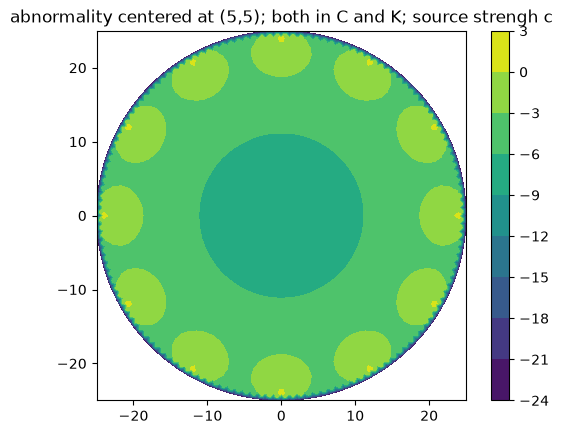

In [10]:
mesh = CircularMesh(25, (0,0), 25)
sources = generate_equidistant_sources(radius=mesh.radius - 0.75*(mesh.radius / mesh.n_rings),
                                       n = 12,
                                       values=np.repeat(mr.c, 12))
Phi = optical_tomography_forward(mesh=mesh,
                                 absorption=mr.get_absorption,
                                 diffusion=mr.get_diffusion,
                                 sources=sources)
mr.plot_function_on_R(mr.get_absorption, -40, 40, -40, 40, "images/test_phi/baseline/absorption_region.png")
mr.plot_function_on_R(mr.get_diffusion, -40, 40, -40, 40, "images/test_phi/baseline/diffusion_region.png")
plot_function_on_mesh(mesh=mesh,
                      z=Phi,
                      savefile="images/test_phi/baseline/phi.png",
                      title="abnormality centered at (5,5); both in C and K; source strengh c",
                      log_scale=True)

### Larger Abnormality

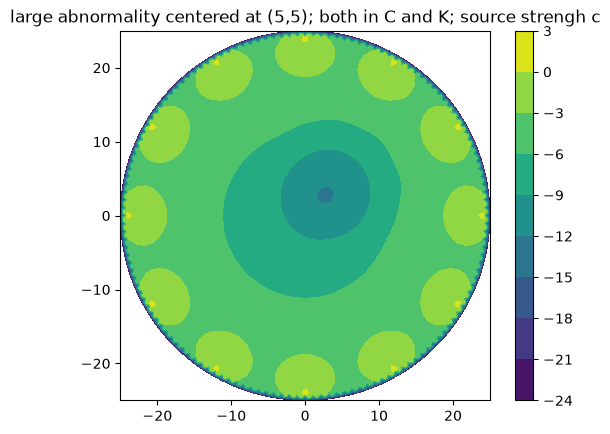

In [14]:
def absorption_large_abnormality(x, y):
    r = 25
    variation_r = 10
    if (x-5)**2 + (y-5)**2 < variation_r**2:
        absorption = 0.05
    elif x**2 + y**2 < r**2:
        absorption = 0.025
    else:
        absorption = 0.0
    return absorption * mr.c


def scattering_large_abnormality(x, y):
    r = 25
    variation_r = 10
    if (x-5)**2 + (y-5)**2 < variation_r**2:
        scattering = 4.0
    elif x**2 + y**2 < r**2:
        scattering = 2.0
    else:
        scattering = 0.0
    return scattering


def diffusion_large_abnormality(x, y):
    absorption = absorption_large_abnormality(x, y) / mr.c # remove the scaling by c
    scattering = scattering_large_abnormality(x, y)
    if absorption == 0.0 and scattering == 0.0: # i.e. we're outside region of interest
        diffusion = 0.0
    else:
        diffusion = mr.c / (3 * (absorption + scattering)) # assuming \bar{f} = 0
    return diffusion


mesh = CircularMesh(25, (0,0), 25)
sources = generate_equidistant_sources(radius=mesh.radius - 0.75*(mesh.radius / mesh.n_rings),
                                       n = 12,
                                       values=np.repeat(mr.c, 12))
Phi = optical_tomography_forward(mesh=mesh,
                                 absorption=absorption_large_abnormality,
                                 diffusion=diffusion_large_abnormality,
                                 sources=sources)
mr.plot_function_on_R(absorption_large_abnormality, -40, 40, -40, 40, "images/test_phi/large_abnormality/absorption_region.png")
mr.plot_function_on_R(diffusion_large_abnormality, -40, 40, -40, 40, "images/test_phi/large_abnormality/diffusion_region.png")
plot_function_on_mesh(mesh=mesh,
                      z=Phi,
                      savefile="images/test_phi/large_abnormality/phi.png",
                      title="large abnormality centered at (5,5); both in C and K; source strengh c",
                      log_scale=True)